# Exercice 5 : Le registre de risques

> **En une phrase :** on ne peut pas tout corriger : on **mesure** chaque risque, puis on dépense le budget là où il réduit le plus de risque.

**Les demandes de l'auditeur traitées ici :** D-06 (registre et plan de traitement des risques). Références : ISO 27001, art. 6.1.2 et 6.1.3.

**Le scénario.** Les ex. 2 à 4 ont révélé des problèmes réels (NAS oublié, sauvegardes en panne, anciens comptes actifs).
La direction a approuvé **50 000 $** pour 2027 et une **politique** : un risque est acceptable si son score résiduel (probabilité × impact) est **au plus 8**.
L'auditeur veut un registre où **chaque** risque a un traitement, et un plan qui respecte le budget.

**Le plan.**
1. Mesurer les risques : probabilité × impact.
2. Les mesures possibles et leur effet.
3. Le plan naïf : la meilleure mesure partout.
4. À vous : un plan dans le budget.
5. Déposer la pièce.

## Étape 0 : exécutez cette cellule en premier
En local, ouvrez **le dossier du chapitre** dans VS Code. Sur Colab, la cellule télécharge le dossier. Elle doit afficher **Prêt : True**.

In [1]:
# Étape 0 : sur Colab, récupère le dossier du chapitre depuis GitHub. En local (VS Code), cette cellule ne fait rien.
import os
if not os.path.exists('auditeur.py'):
    !test -d /content/cours || git clone -q --depth 1 https://github.com/elyesmanai/Code-8INF857---2026.git /content/cours
    %cd "/content/cours/Chapitre 8 - Cadres réglementaires"
print('Prêt :', os.path.exists('auditeur.py'))

Prêt : True


## Étape 1 : Mesurer les risques
**Ce qu'on fait :** pour chaque risque, **probabilité** (1 = rare, 5 = presque certain) × **impact** (1 = négligeable, 5 = catastrophique). On place les risques sur une matrice 5 × 5.

id                          actif                                                            scenario  score
R1                           bd01         Rançongiciel chiffre la base clients ; sauvegardes en échec     20
R2                  Microsoft 365               Prise de contrôle d'un compte administrateur sans MFA     20
R3                        Comptes                      Ancien employé encore actif accède aux données     12
R4 NAS non inventorié (10.0.1.47)                  Fuite de CV de candidats stockés sur un NAS oublié     12
R6                       Employés                            Hameçonnage menant au vol d'identifiants     12
R5                   web01, web02       Panne prolongée de l'hébergement (incendie, panne électrique)     10
R7                          ftp01 Exploitation d'une faille du serveur FTP Debian 10 (fin de support)      6
R8                         Bureau                                           Vol d'un portable chiffré      4


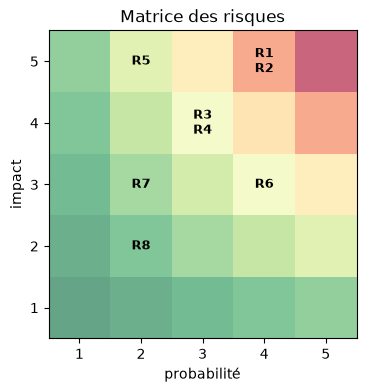

In [2]:
from helper import lire_csv, deposer
import pandas as pd
import matplotlib.pyplot as plt

risques = lire_csv('risques.csv')
risques[['probabilite', 'impact']] = risques[['probabilite', 'impact']].astype(int)
risques['score'] = risques['probabilite'] * risques['impact']
print(risques[['id', 'actif', 'scenario', 'score']].sort_values('score', ascending=False).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 4))
fond = [[(p * i) for p in range(1, 6)] for i in range(1, 6)]
ax.imshow(fond, origin='lower', cmap='RdYlGn_r', extent=(0.5, 5.5, 0.5, 5.5), alpha=0.6)
for (p, i), groupe in risques.groupby(['probabilite', 'impact']):
    ax.text(p, i, '\n'.join(groupe['id']), ha='center', va='center', fontsize=9, weight='bold')
ax.set_xlabel('probabilité'); ax.set_ylabel('impact'); ax.set_title('Matrice des risques');

**👀 Ce qu'on doit voir :** R1 (rançongiciel sur `bd01`, sans sauvegarde) et R2 (admin sans MFA) en haut à droite, à **20**. R8 (vol d'un portable chiffré) en bas à gauche, à 4.
On reconnaît les constats des ex. 2 à 4 : un audit nourrit le registre de risques.

## Étape 2 : Les mesures possibles
**Ce qu'on fait :** pour chaque risque, l'équipe a chiffré une ou deux options. Chaque option a un **traitement** :
- **réduire** : diminuer la probabilité ou l'impact (une mesure de sécurité) ;
- **transférer** : faire porter l'impact par un autre (assurance, sous-traitant) ;
- **éviter** : supprimer l'activité ou l'actif (plus de risque du tout) ;
- **accepter** : ne rien faire, en connaissance de cause.

On calcule le score **résiduel** (après la mesure) et le coût par point de risque retiré.

In [3]:
mesures = lire_csv('mesures.csv')
mesures[['cout', 'probabilite_apres', 'impact_apres']] = mesures[['cout', 'probabilite_apres', 'impact_apres']].astype(int)
mesures['residuel'] = mesures['probabilite_apres'] * mesures['impact_apres']
mesures = mesures.merge(risques[['id', 'score']], left_on='risque', right_on='id').drop(columns='id')
mesures['reduction'] = mesures['score'] - mesures['residuel']
mesures['$ par point'] = (mesures['cout'] / mesures['reduction'].where(mesures['reduction'] > 0)).round(0)
mesures[['risque', 'traitement', 'mesure', 'cout', 'score', 'residuel', '$ par point']]

,risque,traitement,mesure,cout,score,residuel,$ par point
0,R1,réduire,Réparer les sauvegardes de bd01 + copie hors s...,9000,20,6,643.0
1,R1,transférer,Assurance cyber (franchise 25 000 $),14000,20,12,1750.0
2,R2,réduire,MFA obligatoire + accès conditionnel (licences...,6000,20,5,400.0
3,R3,réduire,Processus de départ relié aux RH + revue des a...,4000,12,4,500.0
4,R4,éviter,Retirer le NAS et supprimer les CV de plus de ...,1500,12,0,125.0
5,R4,réduire,Chiffrer le NAS et l'inscrire à l'inventaire,3000,12,8,750.0
6,R5,réduire,Second site de reprise (Montréal) avec bascule...,38000,10,4,6333.0
7,R5,transférer,Contrat de reprise chez un hébergeur partenair...,12000,10,6,3000.0
8,R6,réduire,Formation et simulations d'hameçonnage trimest...,5000,12,6,833.0
9,R7,éviter,Décommissionner ftp01 (remplacé par SFTP sur w...,2000,6,0,333.0


## Étape 3 : Le plan naïf
**Ce qu'on fait :** pour chaque risque, on prend la mesure qui laisse le **plus petit** risque résiduel. C'est ce que tout le monde voudrait.

In [4]:
BUDGET, APPETIT = 50000, 8

def bilan(plan):
    choisi = mesures.loc[plan]
    print(f"Coût total : {choisi['cout'].sum():,} $ (budget : {BUDGET:,} $)".replace(',', ' '))
    trop = choisi[choisi['residuel'] > APPETIT]
    print('Risques résiduels au-dessus de 8 :', list(trop['risque']) or 'aucun')
    return choisi[['risque', 'traitement', 'mesure', 'cout', 'score', 'residuel']]

plan_naif = mesures.sort_values('residuel').groupby('risque').head(1).index
bilan(plan_naif)

Coût total : 65 500 $ (budget : 50 000 $)
Risques résiduels au-dessus de 8 : aucun


,risque,traitement,mesure,cout,score,residuel
4,R4,éviter,Retirer le NAS et supprimer les CV de plus de ...,1500,12,0
9,R7,éviter,Décommissionner ftp01 (remplacé par SFTP sur w...,2000,6,0
6,R5,réduire,Second site de reprise (Montréal) avec bascule...,38000,10,4
3,R3,réduire,Processus de départ relié aux RH + revue des a...,4000,12,4
10,R8,accepter,Aucune mesure supplémentaire (disques déjà chi...,0,4,4
2,R2,réduire,MFA obligatoire + accès conditionnel (licences...,6000,20,5
0,R1,réduire,Réparer les sauvegardes de bd01 + copie hors s...,9000,20,6
8,R6,réduire,Formation et simulations d'hameçonnage trimest...,5000,12,6


**👀 Ce qu'on doit voir :** **65 500 $**, soit 15 500 $ au-dessus du budget. Le coupable : le second site de reprise pour R5, **38 000 $** à lui seul. Tous les risques résiduels sont sous 8, mais le plan est **impossible** à financer.

**❓ Question pour la classe :** une amende en vertu de la Loi 25 peut aller jusqu'à 10 M$ ou 2 % du chiffre d'affaires mondial (sanction administrative). Pour NordHébergement (6,2 M$), 2 % font **124 000 $**. Réparer les sauvegardes coûte 9 000 $. Pourquoi tant d'entreprises ne le font-elles pas ?

*Piste : la probabilité d'être sanctionné paraît faible, et le coût de la mesure est certain. C'est pour ça que la conformité est **auditée** : l'audit rend le risque visible, avec un nom et un chiffre, au lieu de le laisser au hasard.*

## À vous : un plan dans le budget
Choisissez **une mesure par risque** (son numéro de ligne dans le tableau `mesures`) pour que :
1. le coût total soit d'au plus **50 000 $** ;
2. **aucun** risque résiduel ne dépasse **8**.

Partez du plan naïf : un seul risque coûte très cher. Y a-t-il une autre option qui reste sous 8 ?

In [5]:
# À VOUS : un numéro de ligne de « mesures » par risque. Point de départ : le plan naïf.
plan = list(plan_naif)
bilan(plan)

Coût total : 65 500 $ (budget : 50 000 $)
Risques résiduels au-dessus de 8 : aucun


,risque,traitement,mesure,cout,score,residuel
4,R4,éviter,Retirer le NAS et supprimer les CV de plus de ...,1500,12,0
9,R7,éviter,Décommissionner ftp01 (remplacé par SFTP sur w...,2000,6,0
6,R5,réduire,Second site de reprise (Montréal) avec bascule...,38000,10,4
3,R3,réduire,Processus de départ relié aux RH + revue des a...,4000,12,4
10,R8,accepter,Aucune mesure supplémentaire (disques déjà chi...,0,4,4
2,R2,réduire,MFA obligatoire + accès conditionnel (licences...,6000,20,5
0,R1,réduire,Réparer les sauvegardes de bd01 + copie hors s...,9000,20,6
8,R6,réduire,Formation et simulations d'hameçonnage trimest...,5000,12,6


*Réponse :* pour R5 (panne prolongée), remplacez le second site (ligne 6, 38 000 $) par le **contrat de reprise** chez un partenaire (ligne 7, 12 000 $, risque résiduel 6 ≤ 8). Plan : `[0, 2, 3, 4, 7, 8, 9, 10]`, soit **39 500 $**.
On **transfère** le risque au lieu de le réduire soi-même : c'est moins bien sur le papier, mais c'est ce que le budget permet, et la politique l'accepte. Les 10 500 $ restants peuvent servir aux corrections de l'ex3.

## Étape 4 : Déposer la pièce D-06
**Ce qu'on fait :** le registre contient, pour chaque risque, le score initial, le traitement, la mesure, le coût, le score résiduel et un **propriétaire**.

In [6]:
PROPRIETAIRES = {'R1': 'Marc Gagnon (TI)', 'R2': 'Marc Gagnon (TI)', 'R3': 'Julie Tremblay (RH)', 'R4': 'Julie Tremblay (RH)',
                 'R5': 'Nadia Bergeron (Direction)', 'R6': 'Julie Tremblay (RH)', 'R7': 'Marc Gagnon (TI)', 'R8': 'Nadia Bergeron (Direction)'}
choisi = mesures.loc[plan]
registre = pd.DataFrame({'risque': choisi['risque'], 'score_initial': choisi['score'], 'traitement': choisi['traitement'],
                         'mesure': choisi['mesure'], 'cout': choisi['cout'], 'score_residuel': choisi['residuel'],
                         'proprietaire': choisi['risque'].map(PROPRIETAIRES)})
deposer('registre_risques.csv', registre)
registre

Pièce déposée : livrables/registre_risques.csv


,risque,score_initial,traitement,mesure,cout,score_residuel,proprietaire
4,R4,12,éviter,Retirer le NAS et supprimer les CV de plus de ...,1500,0,Julie Tremblay (RH)
9,R7,6,éviter,Décommissionner ftp01 (remplacé par SFTP sur w...,2000,0,Marc Gagnon (TI)
6,R5,10,réduire,Second site de reprise (Montréal) avec bascule...,38000,4,Nadia Bergeron (Direction)
3,R3,12,réduire,Processus de départ relié aux RH + revue des a...,4000,4,Julie Tremblay (RH)
10,R8,4,accepter,Aucune mesure supplémentaire (disques déjà chi...,0,4,Nadia Bergeron (Direction)
2,R2,20,réduire,MFA obligatoire + accès conditionnel (licences...,6000,5,Marc Gagnon (TI)
0,R1,20,réduire,Réparer les sauvegardes de bd01 + copie hors s...,9000,6,Marc Gagnon (TI)
8,R6,12,réduire,Formation et simulations d'hameçonnage trimest...,5000,6,Julie Tremblay (RH)


## Ce que dit l'auditeur
**Ce qu'on fait :** on relance l'auditeur automatique sur tout le dossier `livrables/`. 

In [7]:
import auditeur
auditeur.auditer();

Cabinet Boréal Audit — revue des pièces déposées

⚠️ D-01 Textes applicables et justification          9.3 / 10
      · nis2 : applicabilité « ? » incorrecte
      · nis2 : justification manquante ou trop courte
⚠️ D-02 Inventaire des actifs rapproché du réseau   14.2 / 15  (critique)
      · 10.0.1.47 : aucun propriétaire
      · 10.0.3.58 : aucun propriétaire
✅ D-03 Configuration sécurisée des serveurs        15.0 / 15
❌ D-04 Sauvegardes et test de restauration          0.0 / 10  (critique)
      · web01 / sauvegarde_24h : absent
      · web01 / test_restauration_12_mois : absent
      · bd01 / sauvegarde_24h : absent
      · bd01 / test_restauration_12_mois : absent
⚠️ D-05 Revue des droits d'accès                    11.2 / 15  (critique)
      · anomalie non trouvée : aroy sur bd01 (admin_injustifie)
      · anomalie non trouvée : deploy sur web01 (sans_proprietaire)
      · anomalie non trouvée : pbouchard sur bd01 (parti_actif)
⚠️ D-06 Registre et plan de traitement des risques  

**👀 Ce qu'on doit voir :** avec le plan naïf, D-06 tombe à ⚠️ **7,5 / 15** : l'auditeur coupe la note de moitié pour dépassement du budget. Avec votre plan, ✅ **15 / 15**.
Score : **57 / 100** sans les tâches, **80 / 100** avec les tâches des ex. 1 à 5.

## Ce qu'il faut retenir
- Un risque se **mesure** (probabilité × impact) avant de se traiter : c'est ce qui permet de comparer un NAS oublié et une panne électrique.
- Quatre traitements : **réduire, transférer, éviter, accepter**. Accepter est légitime, si c'est une décision écrite et que le risque est sous l'appétit fixé par la direction.
- Le budget est limité : le meilleur plan n'est pas « la meilleure mesure partout », mais celui qui ramène **tout** sous le seuil au moindre coût.
- Chaque risque a un **propriétaire** : la personne qui décide et qui répond.

**Exercice suivant :** il reste la demande la plus sensible : les **incidents** de l'année, et ce qu'on a dit (ou pas) aux autorités.